# Sentiment Analysis of Product Reviews - NLP + Logistic Regression
End-to-end workflow: data cleaning & EDA -> text preprocessing -> TF-IDF -> tuned Logistic Regression -> model comparison -> evaluation -> explainability.

Data: 200K Amazon product reviews (1-5 stars); a balanced 50K sample is used. Mapping: 1-2 = negative, 3 = neutral, 4-5 = positive.
All heavy logic lives in `src/` so the notebook, scripts and app share one code path.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from wordcloud import WordCloud
from sklearn.metrics import classification_report
from src.config import LABELS, FIG_DIR
from src import data_loader, train as T
from src.preprocessing import clean_text
sns.set_theme(style='whitegrid')

## 1. Data cleaning & EDA

In [2]:
raw = pd.read_json(data_loader.download_raw(), lines=True)
print('raw rows:', len(raw), '| nulls:', raw['text'].isna().sum(), '| duplicate texts:', raw['text'].duplicated().sum())
df = data_loader.build_dataset()   # drops nulls/dupes, samples 50K, maps labels, cleans text
print(df.shape)
df[['text','stars','sentiment','clean_text']].head()

raw rows: 200000 | nulls: 0 | duplicate texts: 574
(50000, 4)


,text,stars,sentiment,clean_text
0,I wish I could give this no star at all. This ...,1,negative,wish could give no star oil not look anything ...
1,"Waist was fine, but the length was ridiculous.",1,negative,waist fine but length ridiculous
2,Could not get it to track in the US. Even with...,1,negative,could not get track u even help correct locati...
3,Bought 2 pairs of this rubber and trashed them...,1,negative,buy pair rubber trash annoy noise use refill
4,Did not work! Had to return and get $ money = ...,1,negative,not work return get money defective already po...


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df['stars'].value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue'); ax[0].set_title('Stars')
df['sentiment'].value_counts()[LABELS].plot.bar(ax=ax[1], color=['#d9534f','#f0ad4e','#5cb85c']); ax[1].set_title('Sentiment classes (neutral is the minority -> class weights)')
plt.tight_layout(); plt.savefig(FIG_DIR/'class_distribution.png', dpi=130); plt.show()

In [4]:
df['n_words'] = df['text'].str.split().str.len()
print(df.groupby('sentiment')['n_words'].describe().round(1))
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x='sentiment', y='n_words', order=LABELS, showfliers=False)
plt.title('Review length (words) by sentiment'); plt.savefig(FIG_DIR/'review_length.png', dpi=130); plt.show()

             count  mean   std  min   25%   50%   75%    max
sentiment                                                   
negative   20000.0  34.9  32.8  2.0  13.0  25.0  45.0  462.0
neutral    10000.0  36.3  35.2  3.0  14.0  26.0  46.0  550.0
positive   20000.0  32.3  33.2  2.0  11.0  22.0  42.0  573.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, cls in zip(axes, LABELS):
    wc = WordCloud(width=600, height=400, background_color='white', max_words=80).generate(' '.join(df.loc[df.sentiment==cls, 'clean_text']))
    ax.imshow(wc); ax.axis('off'); ax.set_title(cls)
plt.tight_layout(); plt.savefig(FIG_DIR/'wordclouds.png', dpi=130); plt.show()

## 2. Text preprocessing
Lowercase, strip URLs/HTML/punctuation, expand contractions, drop stop words, lemmatize. **Negations are kept** (`not`, `no`, `never`, ...) and `n't` is expanded to `not`.

In [6]:
for s in ["Battery life is terrible and it stopped working after a week",
          "I DIDN'T like it, it's not good!! http://spam.com",
          "Great product but shipping was slow"]:
    print(s, '\n  ->', clean_text(s))

Battery life is terrible and it stopped working after a week 
  -> battery life terrible stop work week
I DIDN'T like it, it's not good!! http://spam.com 
  -> not like not good
Great product but shipping was slow 
  -> great product but ship slow


## 3-4. TF-IDF (unigrams + bigrams) and Logistic Regression tuning
GridSearchCV (3-fold, macro-F1) over `C` and `class_weight`. The vectorizer is inside the pipeline so CV is leak-free.

In [7]:
train_df, test_df = T.load_split()
print(len(train_df), len(test_df))
gs = T.tune_logreg(train_df)
print('best:', gs.best_params_, '| CV macro-F1: %.4f' % gs.best_score_)
pd.DataFrame(gs.cv_results_)[['params','mean_test_score','rank_test_score']].sort_values('rank_test_score')

40000 10000
Fitting 3 folds for each of 10 candidates, totalling 30 fits


best: {'clf__C': 0.5, 'clf__class_weight': 'balanced'} | CV macro-F1: 0.6531


,params,mean_test_score,rank_test_score
1,"{'clf__C': 0.5, 'clf__class_weight': 'balanced'}",0.653127,1
3,"{'clf__C': 1, 'clf__class_weight': 'balanced'}",0.653124,2
5,"{'clf__C': 2, 'clf__class_weight': 'balanced'}",0.647808,3
7,"{'clf__C': 5, 'clf__class_weight': 'balanced'}",0.637082,4
9,"{'clf__C': 10, 'clf__class_weight': 'balanced'}",0.629130,5
4,"{'clf__C': 2, 'clf__class_weight': None}",0.628999,6
6,"{'clf__C': 5, 'clf__class_weight': None}",0.627909,7
2,"{'clf__C': 1, 'clf__class_weight': None}",0.625777,8
8,"{'clf__C': 10, 'clf__class_weight': None}",0.624637,9
0,"{'clf__C': 0.5, 'clf__class_weight': None}",0.611850,10


## 5. Model comparison

In [8]:
vec = gs.best_estimator_.named_steps['tfidf']
X_tr, X_te = vec.transform(train_df.clean_text), vec.transform(test_df.clean_text)
y_tr, y_te = train_df.sentiment, test_df.sentiment
table, fitted = T.compare_models(X_tr, y_tr, X_te, y_te, gs.best_params_['clf__C'], gs.best_params_['clf__class_weight'])
table.round(4)

Logistic Regression  acc=0.6932 f1=0.6563 (2s)
Naive Bayes          acc=0.7018 f1=0.5602 (0s)


Linear SVM           acc=0.7047 f1=0.6425 (1s)


Random Forest        acc=0.7024 f1=0.5720 (57s)


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),Train time (s)
0,Logistic Regression,0.6932,0.6591,0.6580,0.6563,1.6847
1,Linear SVM,0.7047,0.6445,0.6431,0.6425,0.5951
2,Random Forest,0.7024,0.6294,0.6016,0.5720,56.9493
3,Naive Bayes,0.7018,0.6424,0.5971,0.5602,0.0477


## 6. Evaluation (Logistic Regression)

              precision    recall  f1-score   support

    negative      0.767     0.727     0.747      4000
     neutral      0.386     0.482     0.429      2000
    positive      0.824     0.765     0.793      4000

    accuracy                          0.693     10000
   macro avg      0.659     0.658     0.656     10000
weighted avg      0.714     0.693     0.702     10000



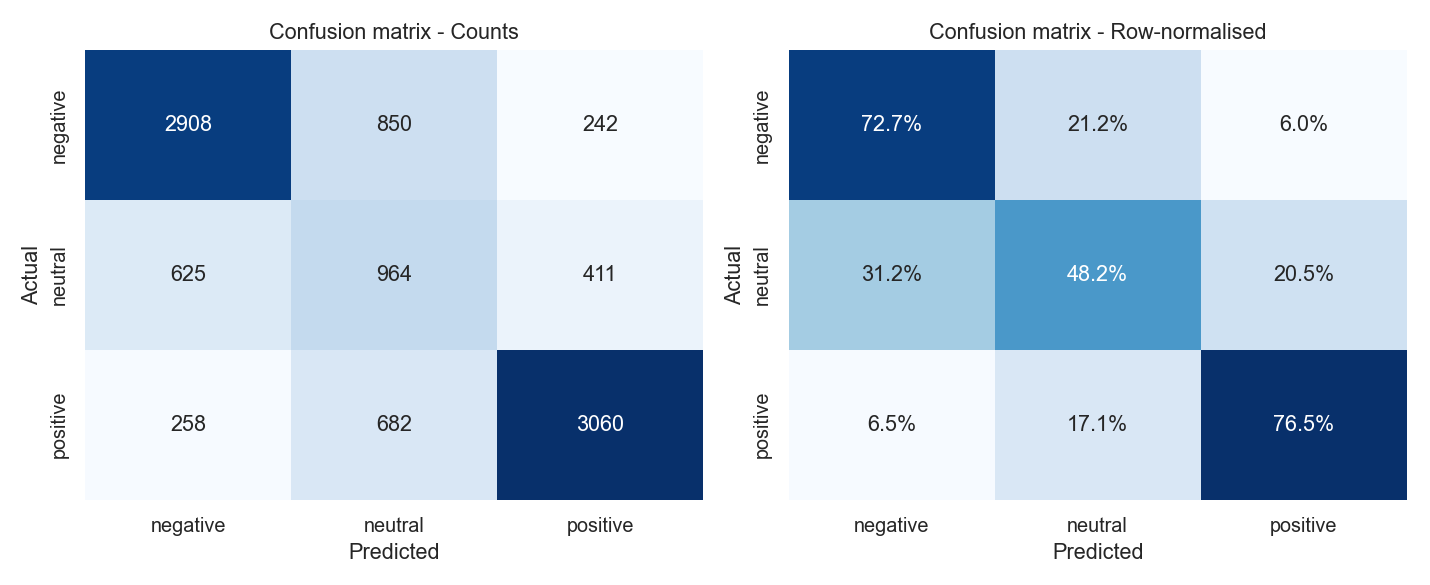

In [9]:
lr = fitted['Logistic Regression']
pred, proba = lr.predict(X_te), lr.predict_proba(X_te)
print(classification_report(y_te, pred, digits=3))
T.plot_confusion(y_te, pred)
from IPython.display import Image; Image(str(FIG_DIR/'confusion_matrix.png'))

In [10]:
err = T.error_analysis(test_df, pred, proba, lr.classes_)
print(f'{len(err)} misclassified of {len(test_df)}')
print('\nMost confident mistakes:')
for _, r in err.head(5).iterrows():
    print(f"[{r.stars}* actual={r.sentiment} pred={r.predicted} conf={r.confidence:.2f}] {r.text[:230]}\n")
print(pd.crosstab(err.stars, err.predicted))

3068 misclassified of 10000

Most confident mistakes:
[3* actual=neutral pred=positive conf=0.98] It is exactly what I wanted. The perfect height and very good looking.

[3* actual=neutral pred=positive conf=0.97] Great for the price.works well.nice design

[3* actual=neutral pred=positive conf=0.95] It’s great for the price and does what you need it for.

[4* actual=positive pred=negative conf=0.94] I did not like these leggings I ordered 3 pair they are thin as paper, poor quality and I won’t be Ordering this ever again.

[3* actual=neutral pred=negative conf=0.94] This was a waste of money for me. I didn't need it. It did not work in my camera. because the camera was not good.

predicted  negative  neutral  positive
stars                                 
1                 0      184        69
2                 0      666       173
3               625        0       411
4               169      553         0
5                89      129         0


**Error analysis takeaways**
- Most errors involve the **neutral (3-star)** class: 3-star reviews mix praise and complaints, and many 2/4-star reviews read the same way. This is label ambiguity, not just model weakness.
- Some "confident mistakes" are mislabelled by the rating itself (a glowing review with a 1-star click, or a product-arrived-broken complaint on a happy review).
- Sarcasm and mixed reviews ("great design but broke in a week") are hard for a bag-of-ngrams model.

## 7. Explainability - top words from coefficients

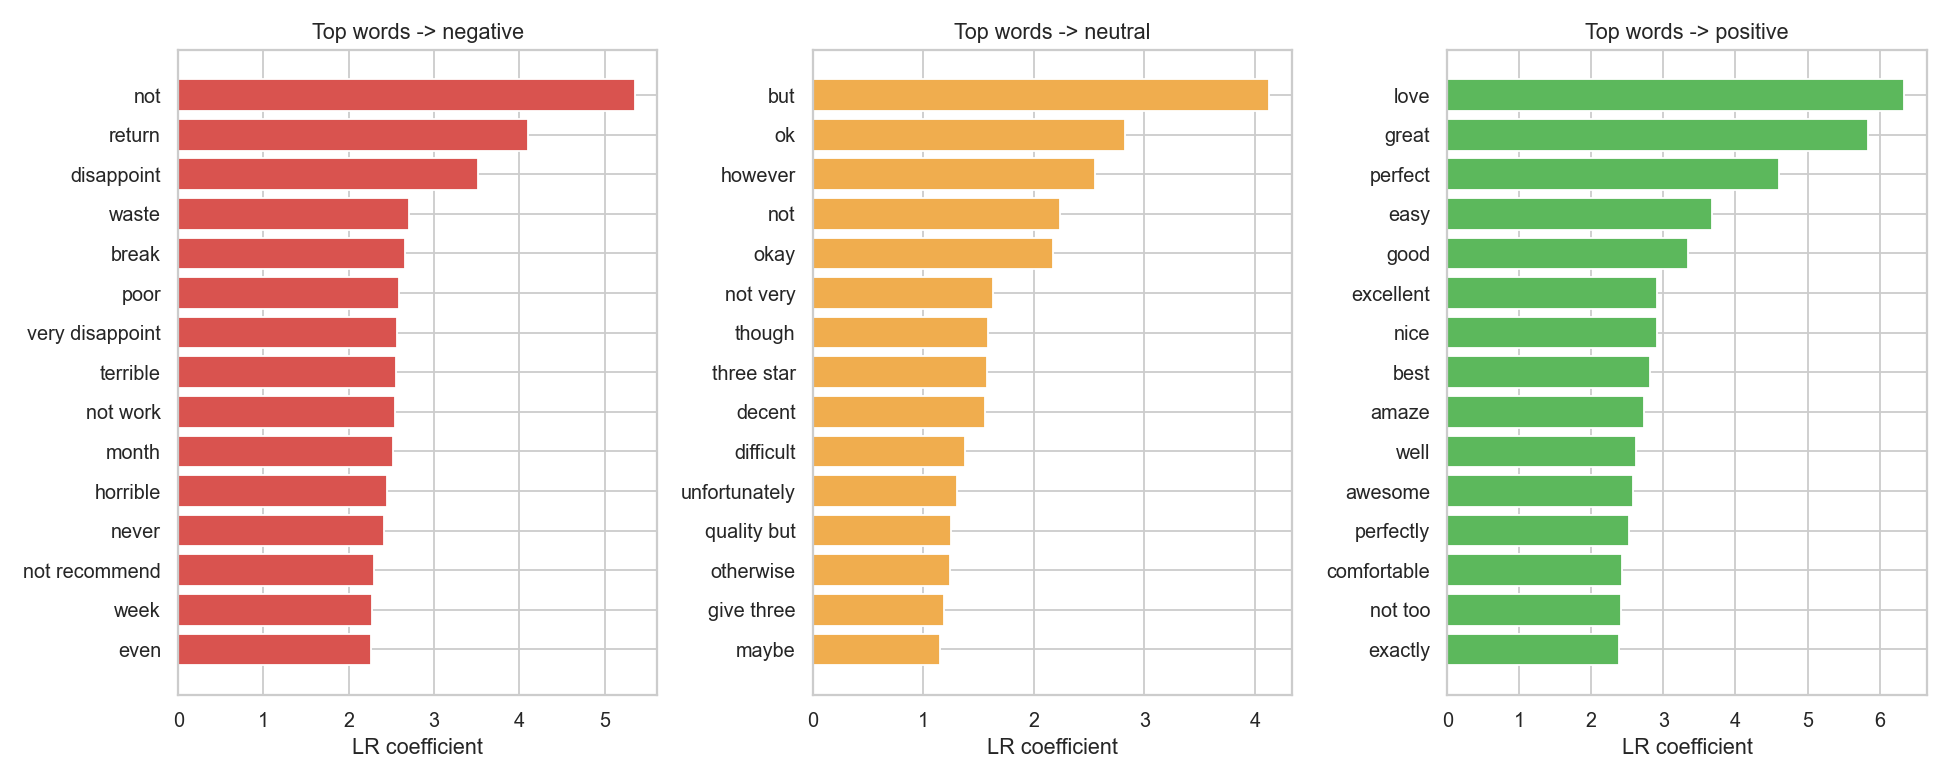

class,negative,neutral,positive
rank,,,
1,not,but,love
2,return,ok,great
3,disappoint,however,perfect
4,waste,not,easy
5,break,okay,good
6,poor,not very,excellent
7,very disappoint,though,nice
8,terrible,three star,best
9,not work,decent,amaze


In [11]:
tw = T.top_words(vec, lr, n=20)
T.plot_top_words(tw)
display(Image(str(FIG_DIR/'top_words.png')))
tw.pivot(index='rank', columns='class', values='word').head(15)

In [12]:
# Optional: LIME for one individual prediction
from src.predict import SentimentPredictor
from src.explain import explain_review
p = SentimentPredictor()
text = 'Great quality but the battery is not good and stopped working after a week'
print(p.predict(text))
print(explain_review(p, text))

{'label': 'negative', 'confidence': 0.5223963415548344, 'probabilities': {'negative': 0.5223963415548344, 'neutral': 0.4200856527722853, 'positive': 0.05751800567288027}}
('negative', [(np.str_('not'), 0.2644195589258075), (np.str_('stopped'), 0.20275539309833082), (np.str_('but'), -0.19038110816167159), (np.str_('Great'), -0.18628943674730497), (np.str_('week'), 0.16951258962735188), (np.str_('good'), -0.10364811159878506), (np.str_('working'), 0.09188770395635398), (np.str_('quality'), -0.08314763456574295)])


## 8. Binary benchmark (context)
Dropping neutral reviews gives the classic positive-vs-negative task - see `python -m src.binary_benchmark` (~0.89 accuracy).

## Deployment
Trained model + vectorizer are in `models/`. Launch the app with `streamlit run app/streamlit_app.py`.